# Exploratory Data Analysis

**Jiayi(Joyce) Qi** 

Building on the cleaned BRFSS 2022 data, this notebook explores how demographic, socioeconomic, and lifestyle characteristics are associated with short sleep. We examine sleep duration, missing information, sample composition, and group differences to provide context for the team's predictive models and planned physical-activity permutation test.

The analysis uses the saved training partition, `brfss_2022_train.csv`, keeping validation and test data separate from exploratory decisions. We derive `short_sleep = 1 - enough_sleep` in memory, so that 1 represents fewer than seven hours of sleep and 0 represents seven or more hours among valid 1–24-hour responses.

We present both sample percentages and survey-weighted summaries to distinguish patterns among respondents from population-oriented estimates. These comparisons are descriptive: they do not include complex-survey confidence intervals or establish statistical significance or causation. The outcome measures short sleep, rather than overall sleep quality or health.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Match the preparation notebook's shared Drive location in Colab.
# Locally, look in the working directory and its Data_preprocessing folder.
PROJECT_DIR = Path.cwd()
try:
    from google.colab import drive
except ImportError:
    data_directories = [PROJECT_DIR, PROJECT_DIR / "Data_preprocessing"]
else:
    drive.mount("/content/drive")
    PROJECT_DIR = Path(
        "/content/drive/Shareddrives/CIS5450 Final Project/Data_Cleaning"
    )
    data_directories = [PROJECT_DIR]

# Keep the training CSV in one of these locations; no personal absolute path.
data_candidates = [folder / "brfss_2022_train.csv" for folder in data_directories]
DATA_FILE = next((path for path in data_candidates if path.is_file()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not find brfss_2022_train.csv. Check the data folder or update PROJECT_DIR."
    )
train_data = pd.read_csv(DATA_FILE)

category_columns = [
    "age_group", "sex", "income_group", "education_level",
    "employment_status", "marital_status", "children_group",
    "physical_activity", "smoking_status", "state",
]
required_columns = category_columns + ["sleep_hours", "enough_sleep", "survey_weight"]
missing_columns = sorted(set(required_columns) - set(train_data.columns))
if missing_columns:
    raise ValueError(f"Training CSV is missing required columns: {missing_columns}")

# Pandas may infer numeric-only categories (for example, education and activity)
# as integers. Convert all categorical inputs to strings so labels and group
# ordering match consistently across columns. This changes only the in-memory data.
train_data[category_columns] = train_data[category_columns].astype("string")

# Create the proposal's short_sleep coding in memory; do not modify or overwrite the CSV.
if not train_data["enough_sleep"].isin([0, 1]).all():
    raise ValueError("enough_sleep must contain only 0 and 1")
train_data["short_sleep"] = 1 - train_data["enough_sleep"]

print(f"Loaded {len(train_data):,} training respondents.")
print("Derived short_sleep = 1 - enough_sleep in memory; the source CSV is unchanged.")
display(train_data.head())


Loaded 256,605 training respondents.
Derived short_sleep = 1 - enough_sleep in memory; the source CSV is unchanged.


,sleep_hours,age_group,sex,income_group,education_level,employment_status,marital_status,children_group,physical_activity,smoking_status,state,survey_weight,stratum_id,psu_id,enough_sleep,short_sleep
0,6,13,2,5,4,2,3,0,2,never,AL,432.100273,11011,2022000002,0,1
1,7,Unknown,2,Unknown,4,7,1,0,1,sometimes,AL,1681.791487,11011,2022000004,1,0
2,7,13,1,Unknown,4,7,1,0,2,never,AL,438.318311,11011,2022000006,1,0
3,7,13,2,8,6,7,2,0,1,former,AL,138.750067,11011,2022000007,1,0
4,8,13,2,7,4,7,3,0,2,never,AL,432.100273,11011,2022000008,1,0


## 1. Establishing the data we can describe

The ten proposed predictors are categorical, even when their stored values look numeric. Their codes identify groups; they are not measured distances. Sleep hours and the survey weight are numeric fields used to describe the data, not additional model predictors. The summaries below show how many categories are observed and where responses are marked `Unknown`, then give a numeric overview of sleep hours and survey weights.


In [4]:
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "savefig.dpi": 160,
})
BLUE, GREEN, GRAY = "#39779E", "#267B65", "#999999"

variable_summary = pd.DataFrame({
    "column": category_columns,
    "observed_dtype": [str(train_data[c].dtype) for c in category_columns],
    "analysis_type": "categorical",
    "observed_categories": [train_data[c].nunique() for c in category_columns],
    "unknown_percent": [
        train_data[c].eq("Unknown").mean() * 100 for c in category_columns
    ],
})
display(variable_summary.round(2))
display(train_data[["sleep_hours", "survey_weight"]].describe().round(2))


,column,observed_dtype,analysis_type,observed_categories,unknown_percent
0,age_group,string,categorical,14,1.79
1,sex,string,categorical,2,0.00
2,income_group,string,categorical,12,20.99
3,education_level,string,categorical,6,0.00
4,employment_status,string,categorical,9,2.31
5,marital_status,string,categorical,7,0.87
6,children_group,string,categorical,5,3.07
7,physical_activity,string,categorical,2,0.00
8,smoking_status,string,categorical,5,7.85
9,state,string,categorical,51,0.00


,sleep_hours,survey_weight
count,256605.00,256605.00
mean,7.03,595.72
std,1.50,1125.64
min,1.00,2.41
25%,6.00,117.45
50%,7.00,275.72
75%,8.00,628.32
max,24.00,54390.52


**Findings from the data overview:** The training set contains **256,605 respondents**. Reported sleep averages **7.03 hours**, with a median of **7** and an interquartile range of **6–8 hours**. Survey weights have a median of **275.72**, a mean of **595.72**, and a maximum of **54,390.52**, indicating a strongly right-skewed distribution.

**Modeling implications:** Treat the ten inputs as categorical rather than standardizing their numeric-looking codes. Fit categorical encoders on training data only and reuse them for validation/test data. Keep sleep hours and survey-design fields outside the predictor matrix; use the survey weight separately when the modeling objective calls for weighted fitting or evaluation.

## 2. How sleep, survey weights, and the target fit together

Before comparing groups, we need to understand both the outcome and the weights used in population-oriented summaries. The three panels below show the weighted distribution of reported sleep duration, how respondent weights are distributed in the training sample, and how the short-sleep class balance changes when weights are applied. The weight histogram uses a logarithmic horizontal axis so a wide range of values can be seen together.


,sample_percent,weighted_percent
Not short sleep: 7-24 h (0),67.38,63.94
Short sleep: 1-6 h (1),32.62,36.06


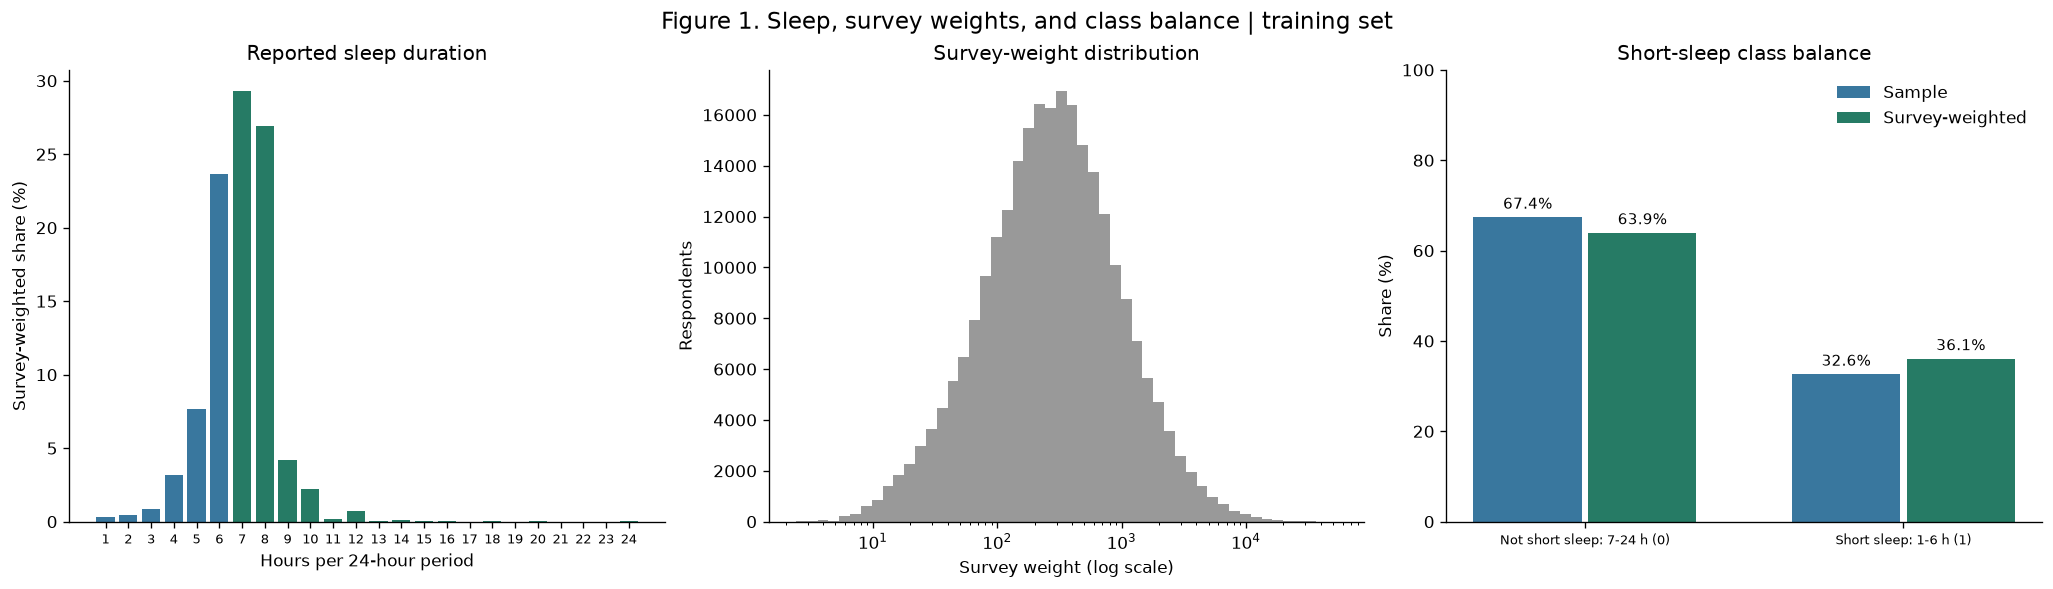

In [5]:
sleep_share = (
    train_data.groupby("sleep_hours")["survey_weight"].sum()
    .reindex(range(1, 25), fill_value=0)
    / train_data["survey_weight"].sum() * 100
)
outcome_summary = pd.DataFrame({
    "sample_percent": train_data["short_sleep"].value_counts(normalize=True),
    "weighted_percent": (
        train_data.groupby("short_sleep")["survey_weight"].sum()
        / train_data["survey_weight"].sum()
    ),
}).reindex([0, 1]) * 100
outcome_summary.index = ["Not short sleep: 7-24 h (0)", "Short sleep: 1-6 h (1)"]
display(outcome_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
axes[0].bar(sleep_share.index, sleep_share,
            color=[GREEN if h >= 7 else BLUE for h in sleep_share.index])
axes[0].set(title="Reported sleep duration", xlabel="Hours per 24-hour period",
            ylabel="Survey-weighted share (%)", xticks=range(1, 25))
axes[0].tick_params(axis="x", labelsize=8)

weight_min = train_data["survey_weight"].min()
weight_max = train_data["survey_weight"].max()
weight_bins = np.logspace(np.log10(weight_min), np.log10(weight_max), 51)
axes[1].hist(train_data["survey_weight"], bins=weight_bins, color=GRAY)
axes[1].set_xscale("log")
axes[1].set(title="Survey-weight distribution", xlabel="Survey weight (log scale)",
            ylabel="Respondents")

positions = np.arange(2)
for offset, column, label, color in [
    (-0.18, "sample_percent", "Sample", BLUE),
    (0.18, "weighted_percent", "Survey-weighted", GREEN),
]:
    bars = axes[2].bar(positions + offset, outcome_summary[column],
                       width=0.34, label=label, color=color)
    axes[2].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
axes[2].set(title="Short-sleep class balance", ylabel="Share (%)",
            xticks=positions, xticklabels=outcome_summary.index, ylim=(0, 100))
axes[2].tick_params(axis="x", labelsize=8)
axes[2].legend(frameon=False)
fig.suptitle("Figure 1. Sleep, survey weights, and class balance | training set", fontsize=14)
plt.show()
plt.close(fig)


**Figure 1 — Findings:** Short sleep accounts for **32.62%** of training respondents and **36.06%** after survey weighting, an increase of **3.44 percentage points**. The complementary non-short-sleep shares are **67.38%** and **63.94%**. The sleep distribution is concentrated around 6–8 hours. The weight distribution spans approximately **2.41–54,390.52**, so respondents contribute very differently to weighted summaries.

**Implications for modeling:** Compare every classifier against an always-non-short-sleep baseline: it would achieve **67.38% unweighted accuracy** on this training sample, despite detecting no short-sleep cases. Report short-sleep precision, recall, F1, and average precision alongside accuracy; state whether each metric uses survey weights. Both outcome classes are well represented, so these proportions alone do not justify resampling. Choose any decision threshold on validation data, then reserve the test set for final evaluation. Survey weights and class weights serve different purposes and should not be treated as interchangeable.

Valid 1–24-hour responses remain in the analysis; meeting the seven-hour minimum does not establish healthy sleep. Exclude both `sleep_hours` and `enough_sleep` when predicting `short_sleep`, because either would reveal the target.

## 3. How much information is unavailable?

The next figure shows the share of training respondents labeled `Unknown` for each categorical predictor. This gives context for interpreting every later group comparison: an `Unknown` category represents an unavailable or invalid response, not a meaningful value such as zero. Retaining it preserves respondents, while the observed missingness still limits what we can conclude about those groups.


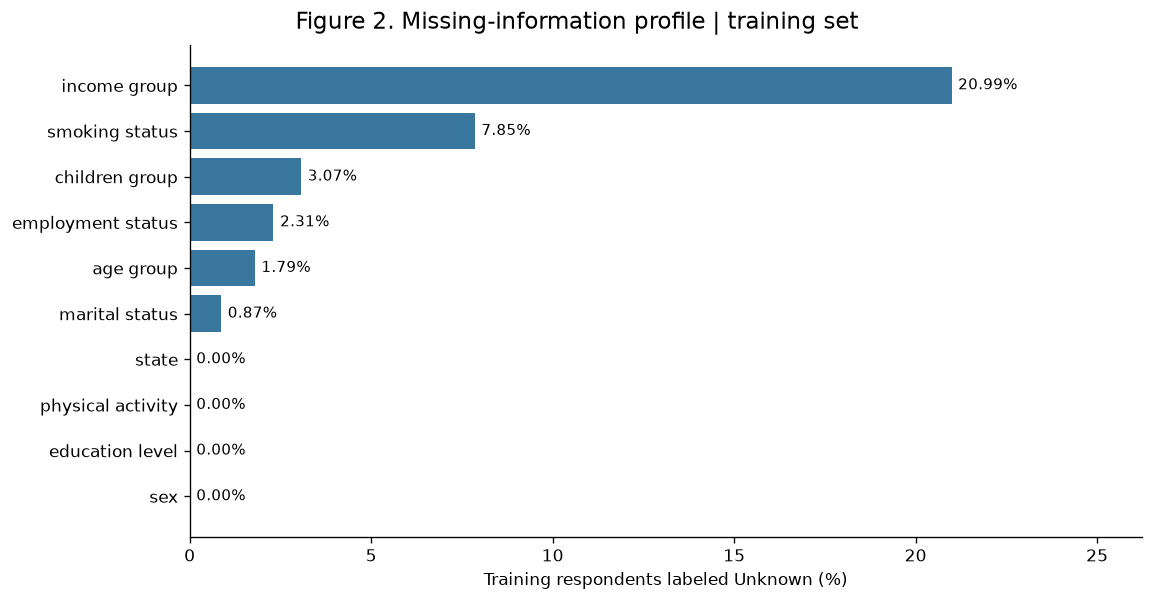

In [6]:
unknown_rates = variable_summary.set_index("column")["unknown_percent"].sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.9), layout="constrained")
bars = ax.barh(unknown_rates.index.str.replace("_", " ", regex=False), unknown_rates,
               color=BLUE)
ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.set(xlabel="Training respondents labeled Unknown (%)",
       xlim=(0, max(unknown_rates.max() * 1.25, 1)))
fig.suptitle("Figure 2. Missing-information profile | training set", fontsize=14)
plt.show()
plt.close(fig)


**Figure 2 — Findings:** Income has the largest Unknown share (**20.99%**), followed by smoking (**7.85%**), household children (**3.07%**), employment (**2.31%**), age (**1.79%**), and marital status (**0.87%**). Education and physical activity have **0% Unknown** because their incomplete records were removed during preparation; this does not mean the original survey had complete responses.

**Implications for modeling:** Preserve the existing Unknown categories in the primary analysis rather than silently dropping respondents or assigning guessed income/smoking values. Their frequency makes missing-information handling a material modeling choice. Compare key findings with a complete-case sensitivity analysis, reporting the resulting sample loss and changes in group composition. Unknown may capture response behavior as well as unavailable characteristics, so coefficients or feature importance for these categories require cautious interpretation.

## 4. Who is represented in the training sample?

Missingness is only one part of the picture. We also need to know which groups are well represented in the respondent sample before interpreting outcome rates. The next figure shows sample counts for age, income, and employment categories. These are respondent counts, not population distributions; survey weights are not applied to this figure. Numeric codes remain category labels rather than exact ages, incomes, or employment quantities.


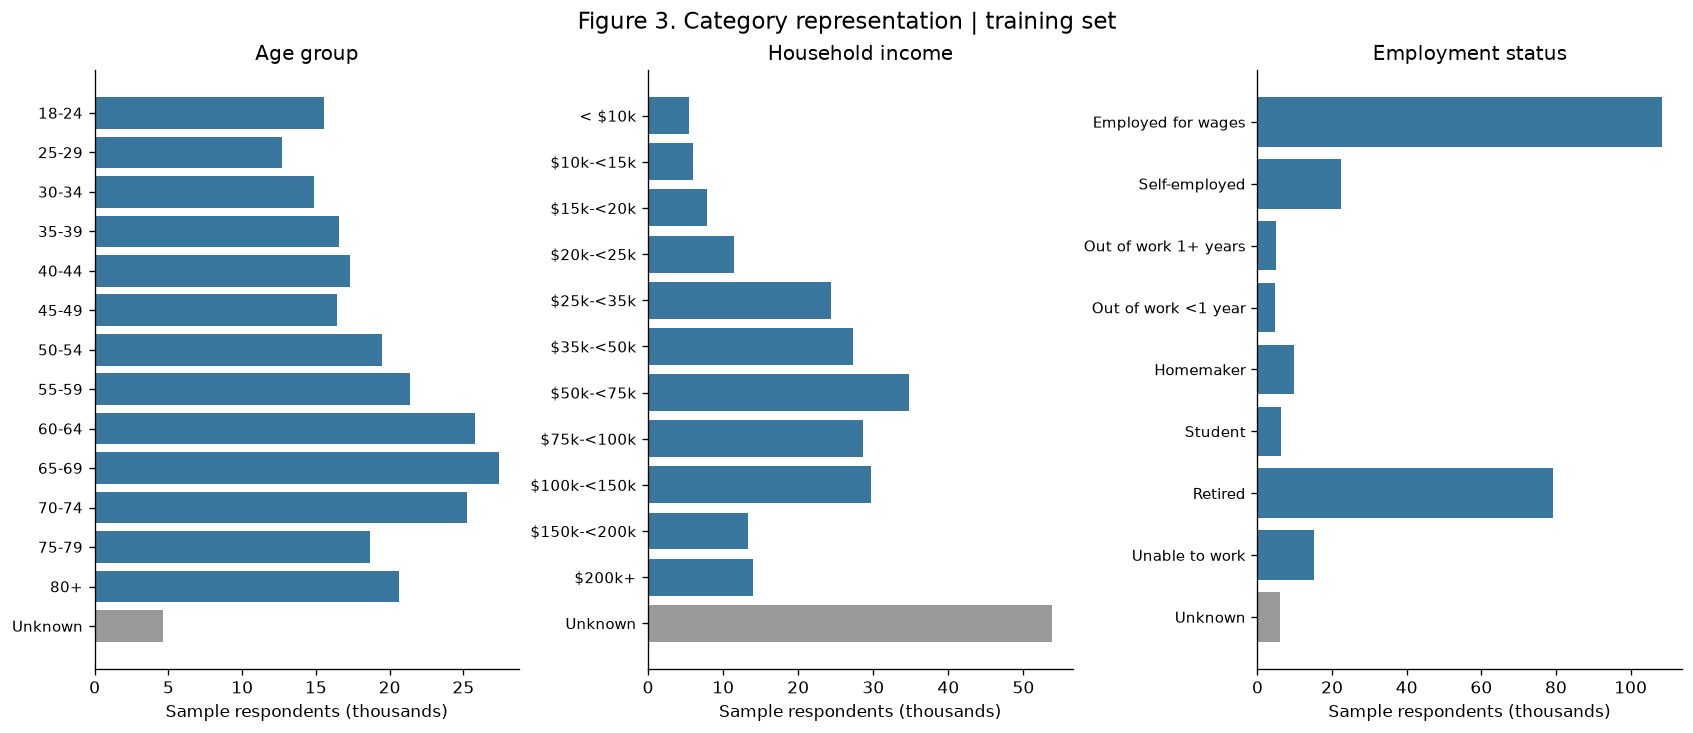

In [7]:
plot_labels = {
    "age_group": dict(zip([str(i) for i in range(1, 14)], [
        "18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
        "55-59", "60-64", "65-69", "70-74", "75-79", "80+",
    ])),
    "income_group": dict(zip([str(i) for i in range(1, 12)], [
        "< $10k", "$10k-<15k", "$15k-<20k", "$20k-<25k", "$25k-<35k",
        "$35k-<50k", "$50k-<75k", "$75k-<100k", "$100k-<150k",
        "$150k-<200k", "$200k+",
    ])),
    "employment_status": dict(zip([str(i) for i in range(1, 9)], [
        "Employed for wages", "Self-employed", "Out of work 1+ years",
        "Out of work <1 year", "Homemaker", "Student", "Retired", "Unable to work",
    ])),
    "education_level": dict(zip([str(i) for i in range(1, 7)], [
        "No school/kindergarten", "Grades 1-8", "Grades 9-11",
        "Grade 12/GED", "Some college/technical", "College graduate",
    ])),
    "physical_activity": {"1": "Any activity", "2": "No activity"},
    "smoking_status": {
        "daily": "Daily", "sometimes": "Sometimes", "former": "Former", "never": "Never",
    },
}
plot_titles = {
    "age_group": "Age group", "income_group": "Household income",
    "employment_status": "Employment status", "education_level": "Education level",
    "physical_activity": "Physical activity", "smoking_status": "Smoking status",
}
for mapping in plot_labels.values():
    mapping["Unknown"] = "Unknown"

fig, axes = plt.subplots(1, 3, figsize=(14, 6), layout="constrained")
for ax, column in zip(axes, ["age_group", "income_group", "employment_status"]):
    order = list(plot_labels[column])
    counts = train_data[column].value_counts().reindex(order, fill_value=0)
    ax.barh([plot_labels[column][x] for x in order], counts / 1000,
            color=[GRAY if x == "Unknown" else BLUE for x in order])
    ax.invert_yaxis()
    ax.set(title=plot_titles[column], xlabel="Sample respondents (thousands)")
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Figure 3. Category representation | training set", fontsize=14)
plt.show()
plt.close(fig)


**Figure 3 — Findings:** Employment groups differ substantially in sample size: **108,361** respondents are employed for wages and **79,207** are retired, compared with **4,604** unemployed for less than a year. Age groups also differ: **27,416** respondents are aged 65–69, compared with **12,691** aged 25–29. Income includes **53,859 Unknown responses**, more than any individual observed income category.

**Implications for modeling:** Compare within-group outcome percentages rather than raw short-sleep counts. Smaller groups may produce less stable estimates and coefficients, so retain group denominators when discussing model results. Use regularization for the logistic baseline and tune tree complexity/minimum leaf size on validation data to limit fitting to sparse categories. Keep age and income categorical in the initial models; their codes do not represent equal measured distances. Sample counts alone cannot describe the population distribution.

## 5. Where does short-sleep prevalence differ across groups?

The proposal focuses on socioeconomic characteristics and lifestyle behaviors, with demographic context. For each requested group—age, income, education, employment, physical activity, and smoking—the table reports the number of respondents, the unweighted short-sleep percentage, and the survey-weighted short-sleep percentage. The formula is `sum(survey_weight × short_sleep) / sum(survey_weight)` within each group. The charts compare each weighted group rate with the overall weighted training rate, marked by a dashed line.

These are unadjusted comparisons. Read the rates as descriptive differences in percentage points, alongside each group's respondent count; a difference alone does not show why groups differ. The proposal's physical-activity permutation test is a separate, prespecified analysis and is not performed by these EDA summaries.


Age group


,respondents,sample_percent,weighted_percent
18-24,15520,32.52,33.51
25-29,12691,35.34,36.68
30-34,14875,38.86,40.62
35-39,16556,39.82,42.27
40-44,17299,38.67,41.47
45-49,16441,38.31,39.72
50-54,19511,38.63,40.24
55-59,21361,36.30,38.55
60-64,25760,33.18,35.98
65-69,27416,28.75,30.23


Household income


,respondents,sample_percent,weighted_percent
< $10k,5472,43.04,41.90
$10k-<15k,6029,42.31,43.93
$15k-<20k,7818,39.45,40.47
$20k-<25k,11480,38.68,40.45
$25k-<35k,24394,36.17,38.86
$35k-<50k,27252,33.64,37.39
$50k-<75k,34743,32.51,37.32
$75k-<100k,28588,30.59,35.52
$100k-<150k,29650,30.03,34.69
$150k-<200k,13335,28.75,31.85


Employment status


,respondents,sample_percent,weighted_percent
Employed for wages,108361,35.82,38.70
Self-employed,22426,31.33,34.63
Out of work 1+ years,4899,40.76,41.02
Out of work <1 year,4604,38.55,39.93
Homemaker,9731,30.76,31.75
Student,6364,30.92,31.09
Retired,79207,24.77,27.39
Unable to work,15087,49.26,49.07
Unknown,5926,35.23,37.47


... (2 outputs left out)

Physical activity


,respondents,sample_percent,weighted_percent
Any activity,196260,30.87,34.52
No activity,60345,38.33,41.05


Smoking status


,respondents,sample_percent,weighted_percent
Daily,20880,45.76,49.60
Sometimes,8014,42.41,45.53
Former,66507,32.11,35.84
Never,141050,30.28,33.66
Unknown,20154,33.22,35.90


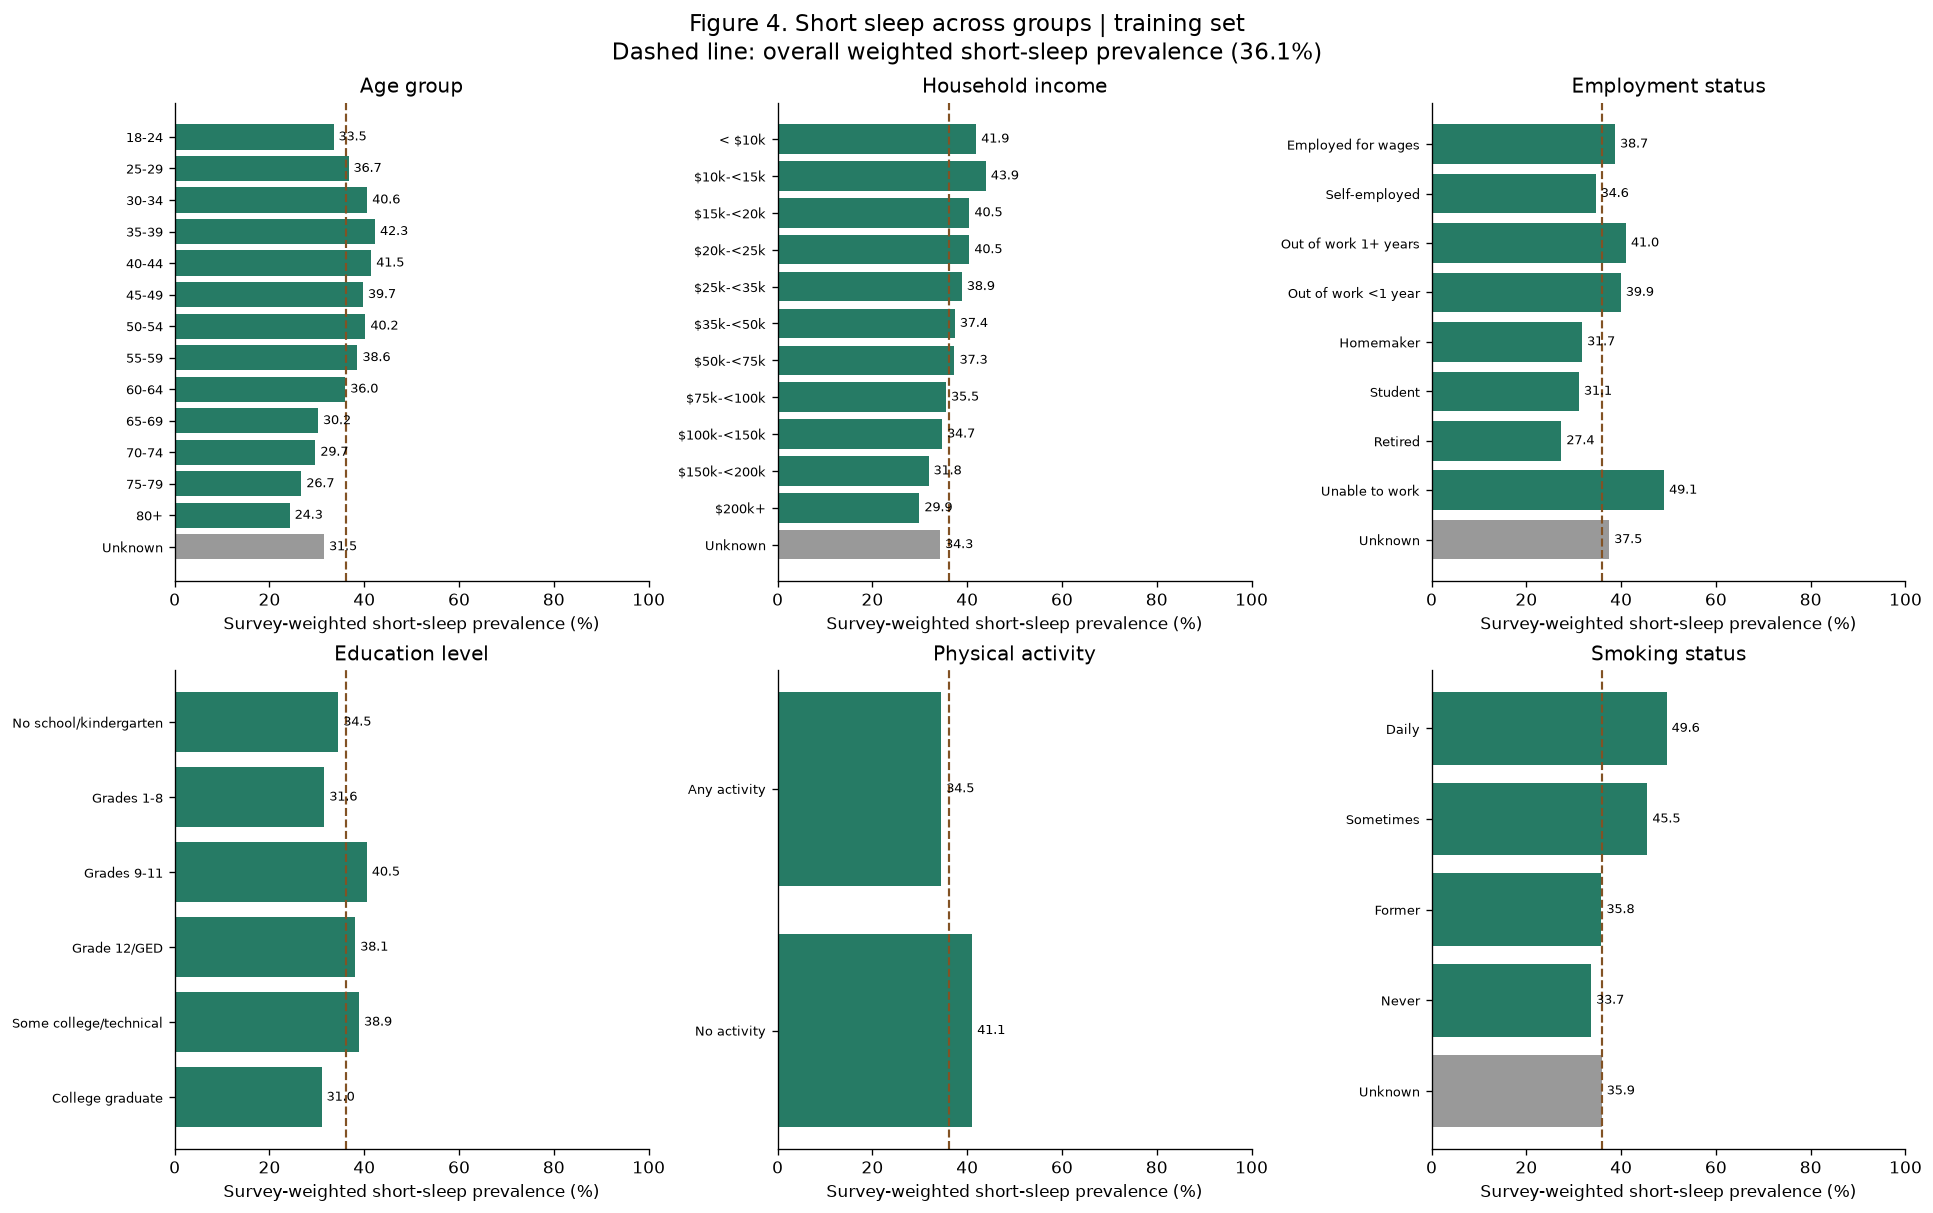

In [8]:
group_summaries = {}
weighted_outcome = train_data.assign(
    weighted_short=train_data["survey_weight"] * train_data["short_sleep"]
)
overall_rate = (
    weighted_outcome["weighted_short"].sum()
    / train_data["survey_weight"].sum() * 100
)
for column in plot_labels:
    table = weighted_outcome.groupby(column).agg(
        respondents=("short_sleep", "size"),
        sample_percent=("short_sleep", "mean"),
        total_weight=("survey_weight", "sum"),
        short_weight=("weighted_short", "sum"),
    ).reindex([level for level in plot_labels[column]
               if level in set(train_data[column])])
    table["sample_percent"] *= 100
    table["weighted_percent"] = table["short_weight"] / table["total_weight"] * 100
    table.index = [plot_labels[column][x] for x in table.index]
    group_summaries[column] = table
    print(plot_titles[column])
    display(table[["respondents", "sample_percent", "weighted_percent"]].round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 10), layout="constrained")
for ax, column in zip(axes.flat, plot_labels):
    table = group_summaries[column]
    colors = [GRAY if x == "Unknown" else GREEN for x in table.index]
    bars = ax.barh(table.index, table["weighted_percent"], color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
    ax.axvline(overall_rate, color="#825224", linestyle="--", linewidth=1.3)
    ax.invert_yaxis()
    ax.set(title=plot_titles[column], xlabel="Survey-weighted short-sleep prevalence (%)", xlim=(0, 100))
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Figure 4. Short sleep across groups | training set\n"
             f"Dashed line: overall weighted short-sleep prevalence ({overall_rate:.1f}%)", fontsize=14)
plt.show()
plt.close(fig)


**Figure 4 — Findings (survey-weighted short-sleep percentages):**

| Comparison | Observed rates | Descriptive interpretation |
|---|---|---|
| Age | **42.27%** at 35–39 versus **24.26%** at 80+ | A difference of **18.01 percentage points**; the age pattern is non-monotonic. |
| Income | **41.90%** below $10,000 versus **29.92%** at $200,000+ | Short sleep generally decreases across income groups, with exceptions; $10,000–<15,000 is **43.93%**. |
| Employment | **49.07%** unable to work versus **27.39%** retired | A difference of **21.68 percentage points**, potentially reflecting age, health, and other factors. |
| Education | **40.55%** in grades 9–11 versus **31.00%** among college graduates | Education differences are not strictly monotonic; grades 1–8 is **31.57%**. |
| Physical activity | **41.05%** with no activity versus **34.52%** with activity | No activity is associated with **6.53 percentage points** more short sleep. |
| Smoking | **49.60%** daily versus **33.66%** never | A difference of **15.94 percentage points**; sometimes and former smoking are **45.53%** and **35.84%**. |

**Implications for modeling:** Retain these socioeconomic, demographic, and lifestyle characteristics for joint model comparison rather than ranking predictors solely by unadjusted rate gaps. The age pattern supports categorical encoding instead of imposing a linear effect on age-group codes. Compare the L2 logistic baseline with tree models to assess whether interactions and more flexible patterns improve validation performance; these charts do not establish that they will. Education's smallest group has only **367 respondents**, so avoid strong conclusions from its rate alone.

The activity difference gives descriptive context for the separately planned permutation test. Its displayed **6.53-point gap is weighted**; define the test statistic and a permutation scheme appropriate to the intended estimand and sampling structure before testing. Do not present these EDA rates as p-values or adjusted effects.

## 6. How much information do the categorical inputs share?

Group differences help identify patterns the models may need to account for, but predictors can also overlap with one another. The final diagnostic measures pairwise association among the ten categorical inputs using Cramér’s V. `Unknown` is retained as a category. Larger values indicate stronger association between a pair of inputs; the diagonal is blank because it would show each variable's association with itself.

This diagnostic can flag pairs that share information and help frame model interpretation. It does not establish that a predictor is redundant, rule out every form of multicollinearity, or test an association with short sleep. All subgroup rates above remain unadjusted and should not be interpreted as causal effects or statistically significant differences.


,first,second,cramers_v
0,employment_status,children_group,0.336
1,age_group,employment_status,0.313
2,age_group,marital_status,0.292
3,age_group,children_group,0.283
4,children_group,smoking_status,0.220
5,education_level,physical_activity,0.212
6,income_group,physical_activity,0.207
7,employment_status,smoking_status,0.206
8,employment_status,physical_activity,0.200
9,employment_status,marital_status,0.196


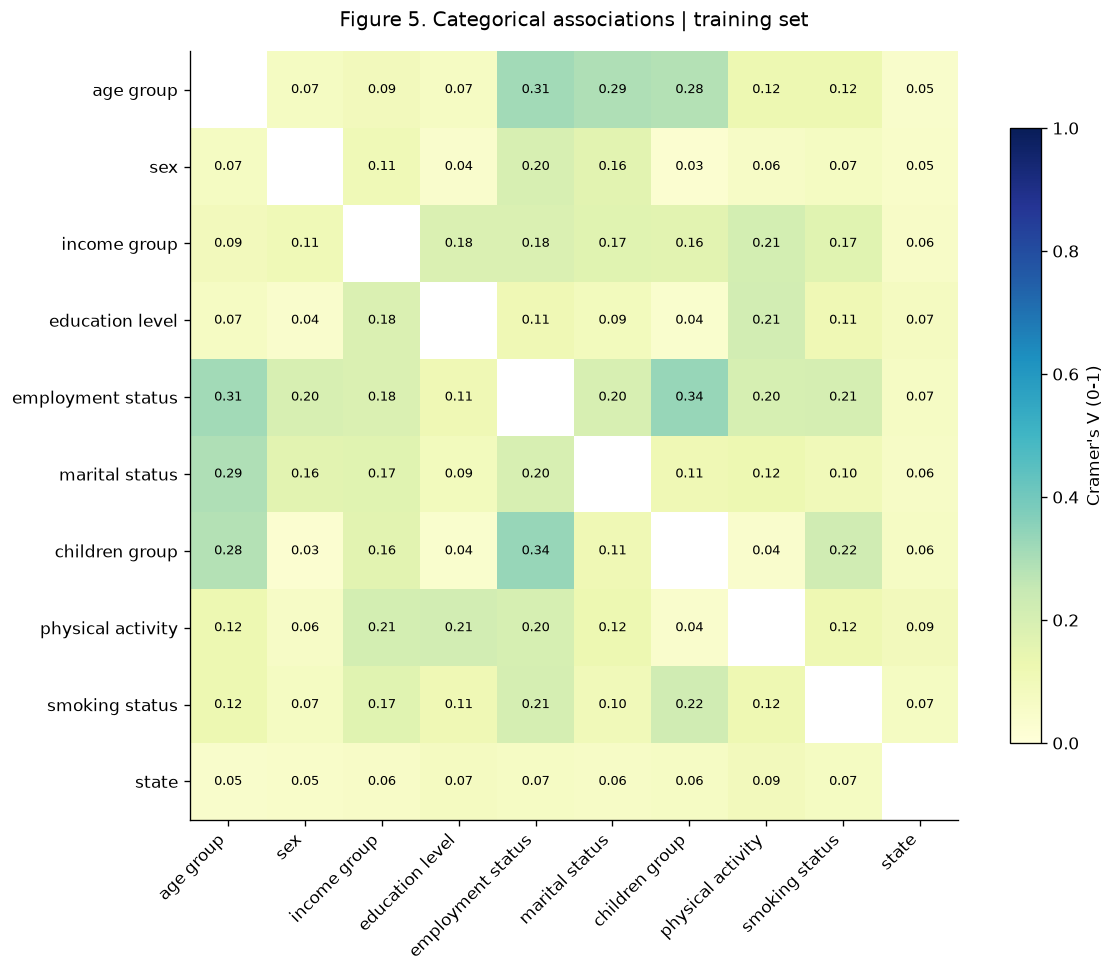

In [9]:
def cramers_v(x, y):
    table = pd.crosstab(x, y).to_numpy(dtype=float)
    denominator = min(table.shape[0] - 1, table.shape[1] - 1)
    if denominator <= 0 or table.sum() == 0:
        return 0.0
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    chi_square = ((table - expected) ** 2 / expected).sum()
    return np.sqrt(chi_square / (table.sum() * denominator))

associations = []
for i, first in enumerate(category_columns):
    for second in category_columns[i + 1:]:
        associations.append({
            "first": first, "second": second,
            "cramers_v": cramers_v(train_data[first], train_data[second]),
        })
association_summary = pd.DataFrame(associations).sort_values(
    "cramers_v", ascending=False
).reset_index(drop=True)
display(association_summary.head(10).round(3))

association_matrix = pd.DataFrame(
    np.nan, index=category_columns, columns=category_columns
)
for row in association_summary.itertuples(index=False):
    association_matrix.loc[row.first, row.second] = row.cramers_v
    association_matrix.loc[row.second, row.first] = row.cramers_v

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
image = ax.imshow(association_matrix.to_numpy(), vmin=0, vmax=1, cmap="YlGnBu")
short_labels = [c.replace("_", " ") for c in category_columns]
ax.set_xticks(range(len(short_labels)), labels=short_labels, rotation=45, ha="right")
ax.set_yticks(range(len(short_labels)), labels=short_labels)
for i in range(len(category_columns)):
    for j in range(len(category_columns)):
        value = association_matrix.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, shrink=0.8, label="Cramer's V (0-1)")
ax.set_title("Figure 5. Categorical associations | training set", pad=15)
plt.show()
plt.close(fig)


**Figure 5 — Findings:** The largest unweighted pairwise Cramér’s V is **0.336** for employment and household children, followed by age–employment (**0.313**), age–marital status (**0.292**), and age–children (**0.283**). Education–activity is **0.212**, and income–activity is **0.207**. These diagnostics show overlapping information without identifying near-perfect pairwise duplication among the ten inputs.

**Implications for modeling:** Retain all ten characteristics for the initial model comparison. Use L2 regularization in the logistic baseline and interpret coefficients as conditional on the other included variables. Related inputs can share predictive information, so a small coefficient or low individual importance does not establish that a characteristic is irrelevant. Cramér’s V is an unweighted input-to-input diagnostic; it neither measures association with short sleep nor rules out all multivariable dependencies.

## EDA findings and implications

The table below connects the main findings to considerations for later analysis. These observations inform the team's choices without determining a particular model, evaluation strategy, or testing procedure.

| Evidence from EDA | Implication or consideration |
|---|---|
| Short sleep accounts for **32.62%** of respondents and **36.06%** after survey weighting | Consider a majority-class baseline and class-specific metrics alongside accuracy. |
| Survey weights range from approximately **2.41 to 54,390.52**, and category sample sizes differ substantially | Report group sizes and distinguish sample percentages from weighted estimates. |
| Income and smoking have **20.99%** and **7.85% Unknown**, respectively | Retain Unknown with caution; sensitivity analysis could assess its influence. |
| Age-group rates are non-monotonic, and numeric-looking input codes represent categories | Treat codes as categories and consider stability in sparse groups. |
| Weighted short-sleep rates differ across age, income, education, employment, activity, and smoking groups | Consider these characteristics jointly; unadjusted gaps do not establish independent effects. |
| The largest pairwise Cramér’s V is **0.336**; no near-perfect pairwise duplication is evident | No input appears nearly duplicated; consider shared information when interpreting models. |
| Short sleep is **41.05%** with no activity versus **34.52%** with activity, a **6.53-point weighted gap** | The gap motivates further testing but does not establish statistical significance. |
| `short_sleep` is derived from `sleep_hours` and is the inverse of `enough_sleep` | Exclude both variables when predicting short sleep to prevent target leakage. |

These findings describe the prepared training partition. Later analyses should reuse the shared partitions, fit preprocessing on training data, and use validation data for model or threshold choices before final test evaluation. The EDA does not provide complex-survey confidence intervals, causal estimates, or hypothesis-test results, and it leaves the prepared data unchanged.
